# 01 - Khám phá dữ liệu (EDA)

Giai đoạn 1-2 của kế hoạch: đọc dữ liệu từ HDFS (mô phỏng bằng thư mục cục bộ `data/raw/`) bằng Spark, khám phá phân phối class, missing values, thống kê Amount/Time.

Notebook này gọi trực tiếp các hàm trong `src/spark_etl.py` - không viết lại logic, chỉ điều phối và trực quan hóa thêm.

In [1]:
import os
import sys

# Bắt buộc set TRƯỚC KHI import pyspark (JVM đọc biến môi trường lúc khởi động).
# Chỉnh lại đường dẫn cho đúng máy của bạn nếu khác.
os.environ.setdefault("JAVA_HOME", r"C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot")
os.environ.setdefault("HADOOP_HOME", r"D:\fraud-detection\hadoop")
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]

sys.path.insert(0, os.path.abspath("../src"))

import matplotlib.pyplot as plt
import seaborn as sns

from config import LABEL_COL, RAW_CSV_PATH
from spark_etl import get_spark_session, read_raw_data, explore_data

sns.set_theme(style="whitegrid")
spark = get_spark_session("EDA-Notebook")
spark

In [2]:
df = read_raw_data(spark, RAW_CSV_PATH)
print(f"Số cột: {len(df.columns)}")
df.printSchema()
df.limit(5).toPandas()

Số cột: 31
root
 |-- Time: double (nullable = true)
 |-- V1: double (nullable = true)
 |-- V2: double (nullable = true)
 |-- V3: double (nullable = true)
 |-- V4: double (nullable = true)
 |-- V5: double (nullable = true)
 |-- V6: double (nullable = true)
 |-- V7: double (nullable = true)
 |-- V8: double (nullable = true)
 |-- V9: double (nullable = true)
 |-- V10: double (nullable = true)
 |-- V11: double (nullable = true)
 |-- V12: double (nullable = true)
 |-- V13: double (nullable = true)
 |-- V14: double (nullable = true)
 |-- V15: double (nullable = true)
 |-- V16: double (nullable = true)
 |-- V17: double (nullable = true)
 |-- V18: double (nullable = true)
 |-- V19: double (nullable = true)
 |-- V20: double (nullable = true)
 |-- V21: double (nullable = true)
 |-- V22: double (nullable = true)
 |-- V23: double (nullable = true)
 |-- V24: double (nullable = true)
 |-- V25: double (nullable = true)
 |-- V26: double (nullable = true)
 |-- V27: double (nullable = true)
 |-- V28: do

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## EDA cơ bản (dùng lại hàm `explore_data` trong `spark_etl.py`)

In ra: tổng số giao dịch, phân phối class (0 = bình thường, 1 = gian lận), số lượng missing values theo cột, thống kê Amount.

In [3]:
explore_data(df)

[EDA] Tổng số giao dịch: 284,807


[EDA] Phân phối class (0 = bình thường, 1 = gian lận):


+-----+------+
|Class| count|
+-----+------+
|    0|284315|
|    1|   492|
+-----+------+



[EDA] Tỉ lệ gian lận: 0.1727%
[EDA] Số lượng missing values theo cột:


+----+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+------+-----+
|Time|V1 |V2 |V3 |V4 |V5 |V6 |V7 |V8 |V9 |V10|V11|V12|V13|V14|V15|V16|V17|V18|V19|V20|V21|V22|V23|V24|V25|V26|V27|V28|Amount|Class|
+----+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+------+-----+
|0   |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0     |0    |
+----+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+---+------+-----+

[EDA] Thống kê Amount:


+-------+------------------+
|summary|            Amount|
+-------+------------------+
|  count|            284807|
|   mean| 88.34961925093077|
| stddev|250.12010924018867|
|    min|               0.0|
|    max|          25691.16|
+-------+------------------+



## Khám phá thêm: tương quan giữa các đặc trưng PCA (V1-V28) và nhãn Class

Lấy mẫu một phần dữ liệu về pandas (toàn bộ 284K dòng vẫn xử lý được nhưng lấy mẫu cho nhanh khi vẽ heatmap).

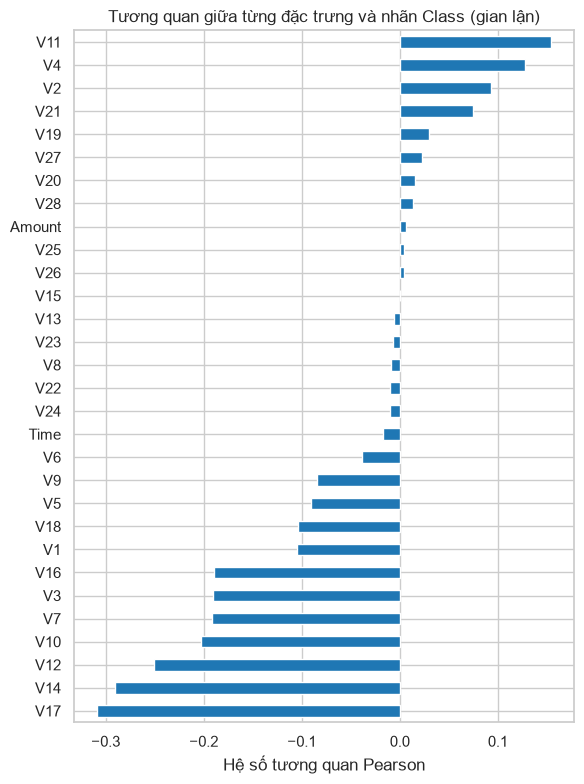

In [4]:
sample_pdf = df.sample(fraction=0.3, seed=42).toPandas()
corr_with_class = sample_pdf.corr(numeric_only=True)[LABEL_COL].drop(LABEL_COL).sort_values()

fig, ax = plt.subplots(figsize=(6, 8))
corr_with_class.plot(kind="barh", ax=ax, color="tab:blue")
ax.set_title("Tương quan giữa từng đặc trưng và nhãn Class (gian lận)")
ax.set_xlabel("Hệ số tương quan Pearson")
plt.tight_layout()
plt.show()

In [5]:
spark.stop()